# What is a token, really?

So, maybe you're an engineer who just got handed a context window limit and an invoice that charges by the token. Or you're a data scientist who has been staring at vocab_size in a config file and nodding along politely in design reviews. In both of those cases, or plenty of others, what you're actually trying to figure out is what the model is reading when you hand it a string.

Ok, so you've probably heard that models don't actually see text, they see tokens. And maybe you've done a bit of digging and learned that a thing called a tokenizer sits in front of the model, doing something called byte pair encoding. But what exactly is that?! How does it help me out or even work?

This notebook pretty much builds the whole idea up in layers. Every single layer is a quick repair for whatever the previous one broke, and every one of them is just a few lines of Python that you can jump in and edit yourself. Just run the cells in order, and then you can go back and change things around; like the corpus, the vocabulary size, or the input text, to see what moves.

Runtime: Your basic CPU is totally fine here. No GPU required, no heavy model weights, and nothing to download except a tiny 1 MB text file to get started.

## Setup

One install cell and a small helper that draws tokens as colored chips. Everything after this is either standard library or numpy until we get to the real tokenizer at the end.

In [ ]:
%pip install -q tokenizers tiktoken regex ipywidgets

import collections, math, re, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import ipywidgets as widgets

# A repeating palette so neighbouring tokens stay visually distinct.
CHIP_COLORS = ["#DCE6F5", "#F6DDE8", "#DDEEE4", "#F6E9D4", "#E4DEF2", "#E8E6DC"]
CHIP_CSS = (
    "display:inline-flex;flex-direction:column;align-items:center;"
    "font-family:ui-monospace,Menlo,monospace;font-size:13px;line-height:1.25;"
    "border:1px solid #1B2A4A;color:#16284D;padding:3px 5px;margin:2px;"
    "white-space:pre;vertical-align:top;"
)

def show_tokens(tokens, ids=None, label=None, unknown=None):
    """Draw a list of token strings as chips, with optional ids underneath."""
    unknown = unknown or set()
    parts = []
    if label:
        parts.append(
            f"<div style='font-family:ui-monospace,monospace;font-size:11px;"
            f"letter-spacing:.12em;text-transform:uppercase;color:#5A6B8C;"
            f"margin:6px 0 4px'>{label}</div>"
        )
    for i, t in enumerate(tokens):
        shown = t.replace(" ", "\u00b7")
        bad = t in unknown
        bg = "#FFE1EF" if bad else CHIP_COLORS[i % len(CHIP_COLORS)]
        border = "#FF3E9A" if bad else "#1B2A4A"
        sub = ""
        if ids is not None:
            sub = (
                f"<span style='font-size:10px;color:#5A6B8C'>{ids[i]}</span>"
            )
        parts.append(
            f"<span style='{CHIP_CSS}background:{bg};border-color:{border}'>"
            f"<span>{shown}</span>{sub}</span>"
        )
    display(HTML(
        "<div style='background:#ECEAE3;padding:8px;border-radius:2px'>"
        + "".join(parts) + "</div>"
    ))

print("ready")

ready


## What if the vocabulary was just words?

A model's vocabulary is a fixed list of the pieces it is allowed to know about. The obvious first guess is that those pieces are words. You take your corpus, collect every distinct word, sort them, and write down the list. That position in the list is the token ID, and it is the only thing that ever leaves the tokenizer.

Splitting text under this scheme is easy. Break on spaces, look up each word, emit its ID. Anything you did not see during training gets mapped to a reserved entry, usually called `<unk>`, for unknown.

In [ ]:
WORD_VOCAB = ["<pad>", "<unk>", "the", "cat", "sat", "on", "mat",
              "a", "dog", "ran", "fast", "and"]
WORD_TO_ID = {w: i for i, w in enumerate(WORD_VOCAB)}
UNK = 1

def word_encode(text):
    ids = []
    for w in text.lower().split():
        w = "".join(ch for ch in w if ch.isalpha() or ch == "'")
        ids.append(WORD_TO_ID.get(w, UNK))
    return ids

def word_decode(ids):
    return " ".join(WORD_VOCAB[i] for i in ids)

ids = word_encode("the cat sat on the mat")
print(ids)
print(word_decode(ids))
show_tokens([WORD_VOCAB[i] for i in ids], ids, label="word level")

[2, 3, 4, 5, 2, 6]
the cat sat on the mat


Now try a sentence with something outside the list. The point of the next cell is to watch information disappear, permanently, before the model has done anything at all.

In [ ]:
def word_demo(text):
    ids = word_encode(text)
    toks = [WORD_VOCAB[i] for i in ids]
    show_tokens(toks, ids, label=f"{len(ids)} tokens", unknown={"<unk>"})
    lost = sum(1 for i in ids if i == UNK)
    print(f"{lost} of {len(ids)} tokens are unrecoverable")

widgets.interact(word_demo, text=widgets.Text(
    value="the sphinx sat on the mat",
    description="text:",
    layout=widgets.Layout(width="70%"),
));

interactive(children=(Text(value='the sphinx sat on the mat', description='text:', layout=Layout(width='70%'))…

A word vocabulary is a closed world, and real text is not. It breaks in a handful of ways that all show up on day one:

- Any word outside the list becomes `<unk>`, which means the model literally cannot represent it or generate it. Proper nouns, typos, and new product names all land here.
- The list gets enormous. English alone runs into the millions once you count inflections, and every entry costs you parameters on both ends of the model.
- It wastes those entries on near duplicates. "play", "played", "playing", and "player" occupy four unrelated slots and share nothing.
- It assumes spaces mean something. Code, URLs, Chinese, Japanese, and Thai all disagree.

## How does an ID become something a model can use?

Before we fix any of that, it is worth being precise about what the model does with these numbers, because it explains why the size of the list matters so much.

Token IDs are labels, not quantities. Token 402 is not twice as much of anything as token 201. So the first thing the model does is throw the number away and use it as a row index into an embedding matrix, a learned table with one row per vocabulary entry and one column per model dimension. That row is the vector the network actually processes.

In [ ]:
rng = np.random.default_rng(0)
D_MODEL = 8                                   # a real one is 2048 to 8192
E = rng.normal(0, 1, size=(len(WORD_VOCAB), D_MODEL)).round(2)

def show_lookup(token="cat"):
    row = WORD_TO_ID[token]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.imshow(E, cmap="PuOr", vmin=-2.5, vmax=2.5, aspect="auto")
    ax.set_yticks(range(len(WORD_VOCAB)))
    ax.set_yticklabels([f"{i}  {w}" for i, w in enumerate(WORD_VOCAB)], fontsize=8)
    ax.set_xticks(range(D_MODEL))
    ax.set_xlabel("model dimension")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.add_patch(plt.Rectangle((-0.5, row - 0.5), D_MODEL, 1,
                               fill=False, edgecolor="#FF3E9A", lw=2.5))
    ax.set_title(f"embedding table, row {row} selected", fontsize=10)
    plt.tight_layout()
    plt.show()
    print(f"E[{row}] = {E[row]}")

widgets.interact(show_lookup, token=widgets.Dropdown(
    options=WORD_VOCAB[2:], value="cat", description="token:"));

interactive(children=(Dropdown(description='token:', index=1, options=('the', 'cat', 'sat', 'on', 'mat', 'a', …

The same table shape shows up again at the other end. After the final layer the model produces one score for every entry in the vocabulary, turns those scores into probabilities, and picks the next token. So the vocabulary size sets the width of the input table and the width of the output layer at the same time.

In [ ]:
d_model = 4096
print(f"embedding + output head parameters at d_model={d_model}\n")
for v in [32_000, 50_257, 100_277, 200_000, 1_000_000]:
    params = 2 * v * d_model
    print(f"  vocab {v:>9,}   {params/1e9:6.2f} B parameters")

embedding + output head parameters at d_model=4096

  vocab    32,000     0.26 B parameters
  vocab    50,257     0.41 B parameters
  vocab   100,277     0.82 B parameters
  vocab   200,000     1.64 B parameters
  vocab 1,000,000     8.19 B parameters


One thing to note though is that a bigger vocabulary is not purely a cost. Longer pieces mean fewer tokens per sentence, which means shorter sequences, cheaper attention, and more text inside the same context window. Choosing a vocabulary size is a trade between those two forces, and we will measure both sides of it later in this notebook.

## How many words would we actually need?

The caveat list claimed the word list gets enormous, which is easy to say and worth actually measuring. Let's pull a real corpus and count.

In [ ]:
URL = ("https://raw.githubusercontent.com/karpathy/char-rnn/"
       "master/data/tinyshakespeare/input.txt")
text = urllib.request.urlopen(URL).read().decode("utf-8")

words = re.findall(r"[a-z']+", text.lower())
counts = collections.Counter(words)
ranked = counts.most_common()
TOTAL = sum(counts.values())

print(f"{len(text):,} characters, {TOTAL:,} word occurrences, "
      f"{len(counts):,} distinct words\n")
print(f"{'rank':>5}  {'word':<8} {'count':>7}  {'share':>7}  {'cumulative':>10}")
running = 0
for i, (w, c) in enumerate(ranked[:12], 1):
    running += c
    print(f"{i:>5}  {w:<8} {c:>7,}  {c/TOTAL:>6.2%}  {running/TOTAL:>10.2%}")

1,115,394 characters, 204,062 word occurrences, 12,631 distinct words

 rank  word       count    share  cumulative
    1  the        6,283   3.08%       3.08%
    2  and        5,690   2.79%       5.87%
    3  to         4,902   2.40%       8.27%
    4  i          4,562   2.24%      10.51%
    5  of         3,759   1.84%      12.35%
    6  you        3,148   1.54%      13.89%
    7  my         3,116   1.53%      15.42%
    8  a          3,006   1.47%      16.89%
    9  that       2,573   1.26%      18.15%
   10  in         2,375   1.16%      19.31%
   11  is         2,079   1.02%      20.33%
   12  not        2,012   0.99%      21.32%


Twelve words, a fifth of the corpus. That is not a quirk of Shakespeare, it is Zipf's law: the second most common word turns up about half as often as the first, the third about a third as often, and so on down the ranks. On log-log axes it is close to a straight line, and it holds for essentially any corpus you point it at.

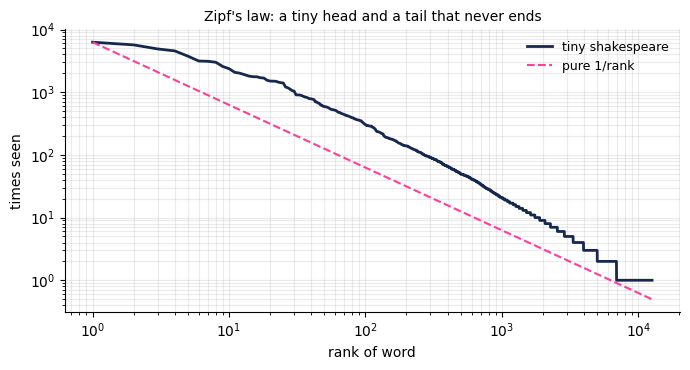

5,704 of 12,631 distinct words (45.2%) appear exactly once


In [ ]:
freqs = np.array([c for _, c in ranked])
ranks = np.arange(1, len(freqs) + 1)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(ranks, freqs, color="#16284D", lw=2, label="tiny shakespeare")
ax.loglog(ranks, freqs[0] / ranks, color="#FF3E9A", lw=1.5, ls="--",
          label="pure 1/rank")
ax.set_xlabel("rank of word")
ax.set_ylabel("times seen")
ax.set_title("Zipf's law: a tiny head and a tail that never ends", fontsize=10)
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=.25, which="both")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

hapax = sum(1 for _, c in ranked if c == 1)
print(f"{hapax:,} of {len(counts):,} distinct words ({hapax/len(counts):.1%}) "
      f"appear exactly once")

That shape has two consequences and neither one is comfortable. The head is so concentrated that a hundred words already account for half the text. The tail is so long that it never resolves, and feeding in more corpus does not fix it, it adds new once-only words at a steady rate. Heaps' law is the name for that second effect, and it means there is no corpus size at which your word list stops growing.

Drag the cutoff below to read both sides of the trade at once.

In [ ]:
cum = np.cumsum(freqs) / TOTAL

def coverage(cutoff=1500):
    cov = cum[cutoff - 1]
    unk = 1 - cov
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.semilogx(ranks, cum * 100, color="#16284D", lw=2)
    ax.axvline(cutoff, color="#FF3E9A", lw=2)
    ax.fill_between(ranks[:cutoff], 0, cum[:cutoff] * 100,
                    color="#FF3E9A", alpha=.13)
    ax.set_xlabel("vocabulary cutoff (words kept, log scale)")
    ax.set_ylabel("% of corpus covered")
    ax.set_ylim(0, 101)
    ax.grid(alpha=.25, which="both")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"keep the top {cutoff:,} words  ->  covers {cov:.1%} of the text")
    if unk > 0:
        print(f"                          ->  {unk:.1%} of tokens arrive as <unk>"
              f"  (1 in {round(1/unk)})")
    kept_once = sum(1 for _, c in ranked[:cutoff] if c == 1)
    print(f"                          ->  {kept_once:,} of those entries appear exactly once")

widgets.interact(coverage, cutoff=widgets.SelectionSlider(
    options=[10, 50, 100, 300, 600, 1000, 1500, 3000, 6000, 9000, len(counts)],
    value=1500, description="cutoff:", continuous_update=False,
    layout=widgets.Layout(width="70%")));

interactive(children=(SelectionSlider(continuous_update=False, description='cutoff:', index=6, layout=Layout(w…

So pick your poison. A 1,500 word vocabulary is small and cheap and throws away roughly one token in seven. A vocabulary large enough to push the unknown rate near zero is mostly entries that fire once in a million tokens, and every one of them still costs a full embedding row and a full output slot that the model will barely ever train.

This distribution is also the thing byte pair encoding goes on to exploit, which is worth flagging now rather than later. Frequency is the only signal it uses, so the head of the distribution collapses into whole-word symbols that cost a single token each, and the tail gets spelled out of short pieces that appear everywhere. The same skew that makes a word vocabulary impossible is what makes subwords cheap.

## What if we split into word pieces instead?

Here is the repair that probably occurred to you during the caveat list. Most of those four "play" entries are the same idea with different endings glued on. If the vocabulary held stems and affixes instead of whole words, entries could be reused across every word that shares them.

In [ ]:
WHOLE_WORDS = ["play", "played", "playing", "player", "players",
               "replay", "replayed", "replaying"]
PIECES = ["re", "play", "ed", "ing", "er", "s"]

def piece_split(word, pieces=PIECES):
    """Greedy longest-match segmentation, just to make the point."""
    out, i = [], 0
    while i < len(word):
        for p in sorted(pieces, key=len, reverse=True):
            if word.startswith(p, i):
                out.append(p)
                i += len(p)
                break
        else:
            out.append(word[i])
            i += 1
    return out

show_tokens(WHOLE_WORDS, range(len(WHOLE_WORDS)), label="one entry per word: 8 entries")
show_tokens(PIECES, range(len(PIECES)), label="shared pieces: 6 entries")

for w in ["players", "replaying", "replayers"]:
    print(f"{w:>12} -> {piece_split(w)}")

     players -> ['play', 'er', 's']
   replaying -> ['re', 'play', 'ing']
   replayers -> ['re', 'play', 'er', 's']


Six entries cover all eight words, and they also spell "replayers", which was never in the word list. That is the whole promise of subword tokenization in one line of output.

So we want pieces. The question is who decides where the seams go. You could write morphology rules by hand, and people did for years, but that approach needs a linguist per language and still has nothing sensible to say about `self.attn_qkv_proj` or a base64 blob. What we actually want is a splitting scheme learned from the data itself, with no notion of what a word even is.

## What is byte pair encoding?

Byte pair encoding (BPE) is that scheme, and it is much dumber than it sounds, which is the best thing about it. It comes from a 1994 data compression trick, repurposed for tokenization in 2015.

Start at the bottom. Every piece of text is bytes, and there are only 256 possible bytes, so a vocabulary that starts as "one entry per byte" can encode anything you will ever be handed. No unknown token, no closed world, no language assumptions. The catch is that byte-per-token sequences are painfully long, so we buy the length back with merges.

The procedure, in full:

1. Count every adjacent pair of symbols in the corpus.
2. Find the most frequent pair and glue it into one new symbol.
3. Record that merge in an ordered list.
4. Repeat until the vocabulary hits the size you budgeted for.

Here it is in about thirty lines. We use characters instead of bytes so the output stays readable, and the marker `▁` stands for the space in front of a word so that "▁low" and "low" stay distinguishable.

In [ ]:
BOW = "\u2581"   # the marker that stands in for a leading space

def merge_pair(symbols, pair):
    """Replace every occurrence of the adjacent pair with one joined symbol."""
    a, b = pair
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and symbols[i] == a and symbols[i + 1] == b:
            out.append(a + b)
            i += 2
        else:
            out.append(symbols[i])
            i += 1
    return out

def train_bpe(corpus, num_merges):
    word_freq = collections.Counter(BOW + w for w in corpus.split())
    splits = {w: list(w) for w in word_freq}
    merges, history = [], [({w: s[:] for w, s in splits.items()}, None, 0)]

    for _ in range(num_merges):
        pairs = collections.Counter()
        for w, freq in word_freq.items():
            s = splits[w]
            for pair in zip(s, s[1:]):
                pairs[pair] += freq
        if not pairs:
            break
        best, count = pairs.most_common(1)[0]
        if count < 2:                      # nothing left worth merging
            break
        for w in splits:
            splits[w] = merge_pair(splits[w], best)
        merges.append(best)
        history.append(({w: s[:] for w, s in splits.items()}, best, count))

    return merges, splits, word_freq, history

CORPUS = ("low low low low low lower lower lowest "
          "newer newer newest newest newest wider widest widest")

merges, splits, word_freq, history = train_bpe(CORPUS, num_merges=30)

for i, (pair) in enumerate(merges, 1):
    print(f"{i:>2}. {pair[0]!r} + {pair[1]!r}  ->  {pair[0] + pair[1]!r}")

 1. '▁' + 'l'  ->  '▁l'
 2. '▁l' + 'o'  ->  '▁lo'
 3. '▁lo' + 'w'  ->  '▁low'
 4. 'e' + 's'  ->  'es'
 5. 'es' + 't'  ->  'est'
 6. 'e' + 'r'  ->  'er'
 7. '▁' + 'n'  ->  '▁n'
 8. '▁n' + 'e'  ->  '▁ne'
 9. '▁ne' + 'w'  ->  '▁new'
10. '▁new' + 'est'  ->  '▁newest'
11. '▁' + 'w'  ->  '▁w'
12. '▁w' + 'i'  ->  '▁wi'
13. '▁wi' + 'd'  ->  '▁wid'
14. '▁low' + 'er'  ->  '▁lower'
15. '▁new' + 'er'  ->  '▁newer'
16. '▁wid' + 'est'  ->  '▁widest'


The one line doing the work in there is `pairs.most_common(1)`, which is an argmax over a frequency distribution with the same lopsided shape as the word counts, just over pairs of symbols rather than whole words. Here is that distribution at the very first step, before any merge has happened.

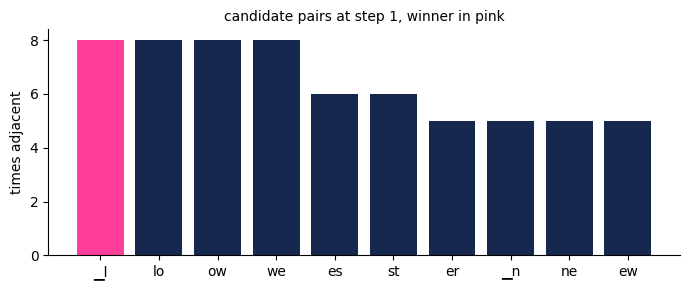

14 distinct pairs, top one seen 8 times, median seen 5 times


In [ ]:
first_state = history[0][0]
pairs = collections.Counter()
for w, freq in word_freq.items():
    for pair in zip(first_state[w], first_state[w][1:]):
        pairs[pair] += freq

top = pairs.most_common(10)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([f"{a}{b}" for (a, b), _ in top], [c for _, c in top], color="#16284D")
ax.bar([f"{a}{b}" for (a, b), _ in top[:1]], [top[0][1]], color="#FF3E9A")
ax.set_ylabel("times adjacent")
ax.set_title("candidate pairs at step 1, winner in pink", fontsize=10)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f"{len(pairs)} distinct pairs, top one seen {top[0][1]} times, "
      f"median seen {int(np.median([c for _, c in pairs.items()]))} times")

Watch what falls out of that list. Nothing in the loop knows what a suffix is, but `es`, `est`, and `er` become single symbols anyway, purely because they are frequent. Frequent whole words like `▁low` also fuse into one symbol, which is exactly what you want, since common words should be cheap. The morphology we were reaching for in the last section arrives on its own as a side effect of counting.

Drag the slider to step through training. The chips are the corpus as the tokenizer currently sees it.

In [ ]:
def show_step(step=0):
    state, pair, count = history[step]
    base = sorted({c for w in word_freq for c in w})
    vocab = base + ["".join(m) for m in merges[:step]]
    ids = {s: i for i, s in enumerate(vocab)}

    if pair:
        print(f"merge {step}: {pair[0]!r} + {pair[1]!r} -> "
              f"{pair[0] + pair[1]!r}   (seen {count} times)")
    else:
        print("no merges yet, every symbol is a single character")
    print(f"vocabulary: {len(vocab)} symbols")

    total = 0
    for w, freq in word_freq.most_common():
        total += freq * len(state[w])
        show_tokens(state[w], [ids[s] for s in state[w]], label=f"{w}  x{freq}")
    print(f"corpus length: {total} tokens")

widgets.interact(show_step, step=widgets.IntSlider(
    min=0, max=len(history) - 1, value=0, description="merges:",
    continuous_update=False, layout=widgets.Layout(width="70%")));

interactive(children=(IntSlider(value=0, continuous_update=False, description='merges:', layout=Layout(width='…

Each merge costs one vocabulary entry and buys back some sequence length. That trade is the entire design space of a tokenizer, and it looks like this.

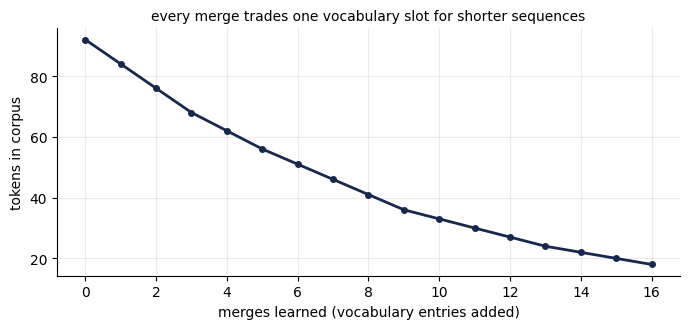

characters: 92 tokens  ->  after 16 merges: 18 tokens


In [ ]:
lengths = []
for state, _, _ in history:
    lengths.append(sum(word_freq[w] * len(s) for w, s in state.items()))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(len(lengths)), lengths, color="#16284D", lw=2, marker="o", ms=4)
ax.set_xlabel("merges learned (vocabulary entries added)")
ax.set_ylabel("tokens in corpus")
ax.set_title("every merge trades one vocabulary slot for shorter sequences", fontsize=10)
ax.grid(alpha=.25)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f"characters: {lengths[0]} tokens  ->  after {len(merges)} merges: {lengths[-1]} tokens")

Notice the ordering. The merge list is not a set, it is a sequence, and encoding new text means replaying those merges in the same order they were learned. That ordered list plus the resulting symbol table is the trained tokenizer, so encoding is about six lines.

In [ ]:
def encode_bpe(text, merges):
    out = []
    for word in text.split():
        symbols = list(BOW + word)
        for pair in merges:
            symbols = merge_pair(symbols, pair)
        out.extend(symbols)
    return out

for probe_text in ["lowest", "the lowest lowlands", "newer widest low"]:
    toks = encode_bpe(probe_text, merges)
    print(f"{probe_text!r:>24} -> {toks}")
    show_tokens(toks, label=f"{len(toks)} tokens")

                'lowest' -> ['▁low', 'est']


   'the lowest lowlands' -> ['▁', 't', 'h', 'e', '▁low', 'est', '▁low', 'l', 'a', 'n', 'd', 's']


      'newer widest low' -> ['▁newer', '▁widest', '▁low']


Anything this tiny corpus never taught it falls apart into characters, and characters it has never seen at all (like `h` or `a`) are not even in the vocabulary. That is not a flaw in the algorithm, it is a statement about the corpus, and it is the whole argument for training on gigabytes instead of sixteen words.

## So what is a tokenizer, and how do we train one?

A modern tokenizer is a small, boring, frozen artifact that ships alongside the model weights. It contains four things:

- a pre-tokenization rule that chops raw text into chunks before BPE ever sees it
- the ordered merge list
- the symbol-to-ID table
- a set of special tokens the model needs but no corpus contains

Training is the loop you just ran with the volume turned up. There is no gradient descent, no loss function, and no GPU. It is a counting job, which is why a real library can train one over a few gigabytes in minutes.

Let's do it properly on the same corpus we counted words in, using the Hugging Face `tokenizers` library, which is the code path production tokenizers are actually built with.

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

def train_real_bpe(corpus, vocab_size):
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=["<|endoftext|>"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),  # all 256 bytes
        show_progress=False,
    )
    tok.train_from_iterator([corpus], trainer)
    return tok

tok1k = train_real_bpe(text, 1000)
sample = "The tokenizer knows nothing of grammar."
enc = tok1k.encode(sample)
show_tokens(enc.tokens, enc.ids, label=f"vocab 1,000: {len(enc.ids)} tokens")
print("decoded:", tok1k.decode(enc.ids))

decoded: The tokenizer knows nothing of grammar.


The `Ġ` you see is that same leading-space marker, byte-level style. Byte-level BPE keeps whitespace attached to the following word, which is why `" the"` and `"the"` are different tokens and why a trailing space in your prompt can quietly change a model's output.

Now the decision that actually matters. Retrain at several vocabulary sizes and measure both sides of the trade.

  vocab     tokens   chars/token
    300    144,519          1.38
    500    104,134          1.92
  1,000     82,687          2.42
  2,000     69,706          2.87
  4,000     61,746          3.24
  8,000     56,995          3.51


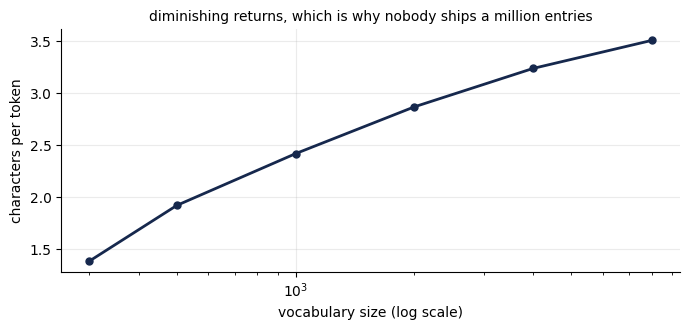

In [ ]:
SIZES = [300, 500, 1000, 2000, 4000, 8000]
probe = text[:200_000]
rows = []
tokenizers_by_size = {}

for v in SIZES:
    t = train_real_bpe(text, v)
    tokenizers_by_size[v] = t
    n = len(t.encode(probe).ids)
    rows.append((v, n, len(probe) / n))

print(f"{'vocab':>7}  {'tokens':>9}  {'chars/token':>12}")
for v, n, ratio in rows:
    print(f"{v:>7,}  {n:>9,}  {ratio:>12.2f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot([r[0] for r in rows], [r[2] for r in rows],
        color="#16284D", lw=2, marker="o", ms=5)
ax.set_xscale("log")
ax.set_xlabel("vocabulary size (log scale)")
ax.set_ylabel("characters per token")
ax.set_title("diminishing returns, which is why nobody ships a million entries", fontsize=10)
ax.grid(alpha=.25)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
def compare_sizes(vocab_size=300, text_to_encode="Shall I compare thee to a summer's day?"):
    t = tokenizers_by_size[vocab_size]
    enc = t.encode(text_to_encode)
    show_tokens(enc.tokens, enc.ids, label=f"vocab {vocab_size:,}: {len(enc.ids)} tokens")

widgets.interact(
    compare_sizes,
    vocab_size=widgets.SelectionSlider(options=SIZES, value=300, description="vocab:"),
    text_to_encode=widgets.Text(value="Shall I compare thee to a summer's day?",
                                description="text:",
                                layout=widgets.Layout(width="80%")),
);

interactive(children=(SelectionSlider(description='vocab:', options=(300, 500, 1000, 2000, 4000, 8000), value=…

Here is the payoff on the distribution we started with. Count how often each token fires under a word vocabulary and under a trained BPE vocabulary of the same size, and the tail is the thing that changes.

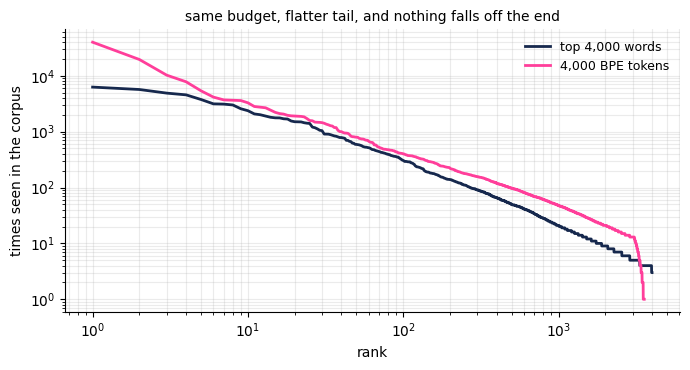

entries seen fewer than 10 times: 2,107 of the words, 396 of the BPE tokens
coverage of the corpus: words 93.8%, BPE 100.0%


In [ ]:
tok4k = tokenizers_by_size[4000]
bpe_ids = tok4k.encode(text).ids
bpe_freqs = np.array(sorted(collections.Counter(bpe_ids).values(), reverse=True))
word_freqs_4k = freqs[:4000]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(np.arange(1, len(word_freqs_4k) + 1), word_freqs_4k,
          color="#16284D", lw=2, label="top 4,000 words")
ax.loglog(np.arange(1, len(bpe_freqs) + 1), bpe_freqs,
          color="#FF3E9A", lw=2, label="4,000 BPE tokens")
ax.set_xlabel("rank")
ax.set_ylabel("times seen in the corpus")
ax.set_title("same budget, flatter tail, and nothing falls off the end", fontsize=10)
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=.25, which="both")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

rare_words = int((word_freqs_4k < 10).sum())
rare_bpe = int((bpe_freqs < 10).sum())
print(f"entries seen fewer than 10 times: {rare_words:,} of the words, "
      f"{rare_bpe:,} of the BPE tokens")
print(f"coverage of the corpus: words {word_freqs_4k.sum()/TOTAL:.1%}, BPE 100.0%")

Same budget of 4,000 entries. The word vocabulary spends a large share of it on entries that fire a handful of times and still leaves part of the corpus unrepresentable. The BPE vocabulary spends its entries on pieces that all get used, and covers everything, because whatever it cannot merge it can always spell out.

### What about the pre-tokenizer?

Merges are only allowed inside chunks that the pre-tokenizer hands over, which stops the trainer from inventing a symbol that spans `"cat sat"`. Modern tokenizers use a regex for this that keeps whitespace with the following word, splits contractions off, and in recent models breaks digits into groups so numbers do not turn into arbitrary chunks.

In [ ]:
import regex   # the `regex` module, for \p{L} style unicode classes

GPT2_PAT = regex.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

sample = "I'm at 98.6 degrees, self.attn_proj(x) == 42!"
show_tokens(GPT2_PAT.findall(sample), label="pre-tokenizer chunks, before BPE runs")

### What does a production tokenizer look like?

The next cell reaches for the tokenizers behind GPT-4 and GPT-4o through `tiktoken`. This needs network access, which Colab has. The interesting result is not the token count on English, it is the ratio between languages, because per-token billing means that ratio is a price.

In [ ]:
try:
    import tiktoken
    enc4 = tiktoken.get_encoding("cl100k_base")     # GPT-4
    enc4o = tiktoken.get_encoding("o200k_base")     # GPT-4o, 200k vocab

    samples = {
        "english": "The tokenizer is trained once and then frozen forever.",
        "hindi":   "टोकनाइज़र को एक बार प्रशिक्षित किया जाता है।",
        "thai":    "โทเคนไนเซอร์ถูกฝึกเพียงครั้งเดียว",
        "code":    "def merge_pair(symbols, pair): return [a+b for a, b in symbols]",
        "digits":  "The order total came to 1234567.89 dollars.",
    }
    print(f"{'':>9}  {'chars':>6}  {'cl100k':>7}  {'o200k':>7}  {'chars/tok':>10}")
    for name, s in samples.items():
        a, b = len(enc4.encode(s)), len(enc4o.encode(s))
        print(f"{name:>9}  {len(s):>6}  {a:>7}  {b:>7}  {len(s)/a:>10.2f}")

    print()
    show_tokens([enc4.decode([i]) for i in enc4.encode("strawberry blueberry")],
                enc4.encode("strawberry blueberry"),
                label="GPT-4 tokens: the model never sees the letters")
except Exception as e:
    print("tiktoken needs network access to download its encodings.")
    print(f"({type(e).__name__}) Skip this cell if you are running offline.")

            chars   cl100k    o200k   chars/tok
  english      54       10       10        5.40
    hindi      44       45       14        0.98
     thai      33       35       14        0.94
     code      63       19       19        3.32
   digits      43       13       13        3.31



That last chip row is the answer to the strawberry riddle. The model is not looking at letters, it is looking at two or three integers, so counting the r's is a genuinely awkward task rather than a reasoning failure.

A few more things worth knowing before you go near one in production:

- The tokenizer is frozen once model training starts. Retraining it invalidates every learned embedding, so you cannot swap it in later.
- Token counts are not word counts and not character counts. English averages roughly 3 to 4 characters per token, code and non-English text average much less.
- If your training corpus is 95 percent English, the merges will spend themselves on English and everything else fragments, which shows up directly on your bill.
- BPE is not the only option. WordPiece, used by BERT, picks merges by likelihood gain rather than raw frequency, and Unigram, offered through SentencePiece, starts with a large candidate vocabulary and prunes it down. The mental model transfers.

## Connecting the dots

Let's follow one string all the way through, using the tokenizer we trained above and a randomly initialized embedding table standing in for a model.

In [ ]:
tok = tokenizers_by_size[4000]
prompt = "Shall I compare thee"

# 1. pre-tokenize into chunks
chunks = GPT2_PAT.findall(prompt)
print("1. chunks      :", chunks)

# 2. replay merges inside each chunk, look up ids
enc = tok.encode(prompt)
print("2. tokens      :", enc.tokens)
print("3. ids         :", enc.ids)
show_tokens(enc.tokens, enc.ids, label="what the model receives")

# 4. ids index rows of the embedding table
V = tok.get_vocab_size()
d_model = 64
E = np.random.default_rng(0).normal(0, 0.02, size=(V, d_model))
x = E[enc.ids]
print(f"4. embeddings  : E{E.shape}[ids] -> x{x.shape}")

# 5. the model runs, and the last layer scores every vocabulary entry
logits = np.random.default_rng(1).normal(0, 1, size=V)
probs = np.exp(logits - logits.max()); probs /= probs.sum()
next_id = int(np.argmax(probs))
print(f"5. logits      : one score per vocabulary entry, shape {logits.shape}")

# 6. the sampled id goes back through the table and becomes text
print(f"6. next token  : id {next_id} -> {tok.decode([next_id])!r} (untrained, so it is noise)")
print(f"7. round trip  : {tok.decode(enc.ids)!r}")

1. chunks      : ['Shall', ' I', ' compare', ' thee']
2. tokens      : ['Shall', 'ĠI', 'Ġcomp', 'are', 'Ġthee']
3. ids         : [1226, 292, 1086, 484, 412]


4. embeddings  : E(4000, 64)[ids] -> x(5, 64)
5. logits      : one score per vocabulary entry, shape (4000,)
6. next token  : id 860 -> 'ace' (untrained, so it is noise)
7. round trip  : 'Shall I compare thee'


Steps 1 through 3 are the tokenizer. Steps 4 through 6 are the model. Step 7 is the tokenizer again, running backwards, and detokenizing is just concatenation, which is why the space marker matters so much: it is what puts the whitespace back.

## Where to next?

Change the corpus in the `train_real_bpe` cell to something in your own domain, retrain at a couple of vocabulary sizes, and compare characters per token against `cl100k_base`. If your domain is logs, code, or a language that is not English, the gap is usually large enough to be worth a conversation.

- [Neural Machine Translation of Rare Words with Subword Units](https://arxiv.org/abs/1508.07909)
- [SentencePiece: A simple and language independent subword tokenizer](https://arxiv.org/abs/1808.06226)
- [karpathy/minbpe](https://github.com/karpathy/minbpe)
- [openai/tiktoken](https://github.com/openai/tiktoken)
- [Hugging Face NLP Course, chapter 6](https://huggingface.co/learn/nlp-course/chapter6/1)